# Ensemble methods on the LKR exchange rate: bagging vs boosting vs voting vs stacking

Predicts the **next-day % change** of the USD/LKR mid rate (CBSL TT buying/selling average).
**Only `lkr_fx_clean.csv` is needed** in the same folder; all code is inside this notebook.
Run **Kernel -> Restart & Run All** (the stacking and robustness cells take a few minutes).

## 0a. Helper code: data loading, features, metrics
Run first. Nothing to edit.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd


CROSS = ["GBP", "EUR", "JPY"]


def load(path):
    return pd.read_csv(path, parse_dates=["date"]).sort_values("date").reset_index(drop=True)


def make_features(df, cur="USD"):
    mid = (df[f"{cur}_buy"] + df[f"{cur}_sell"]) / 2
    lp = np.log(mid)
    r = lp.diff() * 100                                   
    X = pd.DataFrame({"date": df["date"], "mid": mid, "ret_0": r})
    for k in (1, 2, 3, 4, 9):
        X[f"ret_{k}"] = r.shift(k)
    for w in (5, 20):
        X[f"ret_mean_{w}"] = r.rolling(w).mean()
        X[f"ret_std_{w}"] = r.rolling(w).std()
    for w in (20, 60):
        X[f"dev_ma{w}"] = (lp - np.log(mid.rolling(w).mean())) * 100
    X["spread_pct"] = (df[f"{cur}_sell"] - df[f"{cur}_buy"]) / mid * 100
    X["dow"] = df["date"].dt.dayofweek
    X["month"] = df["date"].dt.month
    for c in CROSS:                                       
        if c != cur and f"{c}_buy" in df:
            cm = (df[f"{c}_buy"] + df[f"{c}_sell"]) / 2
            X[f"x_{c}_0"] = (np.log(cm).diff() * 100) - r
    X["target"] = r.shift(-1)                            
    return X.dropna().reset_index(drop=True)


def _metrics(name, y, p, px):
    err = y - p
    lvl_true, lvl_pred = px * np.exp(y / 100), px * np.exp(p / 100)
    nz = np.isfinite(p) & (p != 0) & (y != 0)
    return {
        "model": name,
        "RMSE (% return)": float(np.sqrt(np.mean(err ** 2))),
        "MAE (% return)": float(np.mean(np.abs(err))),
        "Direction acc.": float(np.mean(np.sign(p[nz]) == np.sign(y[nz]))) if nz.any() else np.nan,
        "RMSE (Rs level)": float(np.sqrt(np.mean((lvl_true - lvl_pred) ** 2))),
        "MAE (Rs level)": float(np.mean(np.abs(lvl_true - lvl_pred))),
    }

## 0b. Ensemble code: models, voting, stacking
Run second. Nothing to edit.

In [2]:
import time
import numpy as np
import pandas as pd
from sklearn.base import clone
from sklearn.ensemble import (RandomForestRegressor, ExtraTreesRegressor, BaggingRegressor,
                              AdaBoostRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor)
from sklearn.linear_model import Ridge
from sklearn.model_selection import TimeSeriesSplit
from sklearn.tree import DecisionTreeRegressor


try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None
try:
    from lightgbm import LGBMRegressor
except ImportError:
    LGBMRegressor = None
try:
    from catboost import CatBoostRegressor
except ImportError:
    CatBoostRegressor = None

FAMILY = {"Decision Tree (single)": "reference",
          "Random Forest": "bagging", "Extra Trees": "bagging", "Bagging (trees)": "bagging",
          "AdaBoost": "boosting", "Gradient Boosting": "boosting", "HistGradientBoosting": "boosting",
          "XGBoost": "boosting", "LightGBM": "boosting", "CatBoost": "boosting"}

DEFAULTS = {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05, "min_samples_leaf": 20, "seed": 42}


def build_models(p=None):
    p = {**DEFAULTS, **(p or {})}
    n, d, lr, leaf, s = p["n_estimators"], p["max_depth"], p["learning_rate"], p["min_samples_leaf"], p["seed"]
    m = {
        "Decision Tree (single)": DecisionTreeRegressor(max_depth=d, min_samples_leaf=leaf, random_state=s),
        "Random Forest": RandomForestRegressor(n_estimators=n, max_depth=d, min_samples_leaf=leaf, max_features=0.5,
                                                n_jobs=-1, random_state=s),
        "Extra Trees": ExtraTreesRegressor(n_estimators=n, max_depth=d, min_samples_leaf=leaf, max_features=0.5,
                                            n_jobs=-1, random_state=s),
        "Bagging (trees)": BaggingRegressor(estimator=DecisionTreeRegressor(max_depth=d, min_samples_leaf=leaf),
                                            n_estimators=n, n_jobs=-1, random_state=s),
        "AdaBoost": AdaBoostRegressor(estimator=DecisionTreeRegressor(max_depth=min(d, 3)),
                                      n_estimators=n, learning_rate=lr, random_state=s),
        "Gradient Boosting": GradientBoostingRegressor(n_estimators=n, max_depth=min(d, 5), learning_rate=lr,
                                                       subsample=0.8, random_state=s),
        "HistGradientBoosting": HistGradientBoostingRegressor(max_iter=n, max_depth=d, learning_rate=lr, random_state=s),
    }
    if XGBRegressor is not None:
        m["XGBoost"] = XGBRegressor(n_estimators=n, max_depth=d, learning_rate=lr, subsample=0.8,
                                    colsample_bytree=0.8, random_state=s, n_jobs=-1)
    if LGBMRegressor is not None:
        m["LightGBM"] = LGBMRegressor(n_estimators=n, max_depth=d, learning_rate=lr, subsample=0.8,
                                      subsample_freq=1, colsample_bytree=0.8, random_state=s, verbose=-1)
    if CatBoostRegressor is not None:
        m["CatBoost"] = CatBoostRegressor(iterations=n, depth=min(d, 8), learning_rate=lr, random_seed=s, verbose=0)
    return m


def available_models():
    return list(build_models().keys())


def run_ensemble_experiment(X, train_end="2023-12-31", params=None, selected=None,
                            vote_members=None, stack_members=None, n_splits=5):
    models = build_models(params)
    selected = [m for m in (selected or list(models)) if m in models]
    vote_members = [m for m in (vote_members or []) if m in selected]
    stack_members = [m for m in (stack_members or []) if m in selected]

    feats = [c for c in X.columns if c not in ("date", "mid", "target")]
    tr = (X["date"] <= pd.Timestamp(train_end)).values
    Xtr, Xte = X.loc[tr, feats].reset_index(drop=True), X.loc[~tr, feats].reset_index(drop=True)
    ytr, yte = X.loc[tr, "target"].values, X.loc[~tr, "target"].values
    px_te = X.loc[~tr, "mid"].values

    preds = {"Naive (tomorrow = today)": np.zeros(len(yte))}
    secs, imps = {}, {}
    for name in selected:
        t0 = time.perf_counter()
        est = models[name].fit(Xtr, ytr)
        secs[name] = time.perf_counter() - t0
        preds[name] = np.asarray(est.predict(Xte), dtype=float)
        if hasattr(est, "feature_importances_"):
            imps[name] = pd.Series(est.feature_importances_, feats)

    if len(vote_members) >= 2:
        t0 = time.perf_counter()
        preds["Voting ensemble (average)"] = np.mean([preds[m] for m in vote_members], axis=0)
        secs["Voting ensemble (average)"] = sum(secs[m] for m in vote_members) + (time.perf_counter() - t0)

    weights = None
    if len(stack_members) >= 2:
        t0 = time.perf_counter()
        oof = np.full((len(ytr), len(stack_members)), np.nan)
        for tr_i, va_i in TimeSeriesSplit(n_splits=n_splits).split(Xtr):      # expanding window, no leakage
            for j, name in enumerate(stack_members):
                est = clone(models[name]).fit(Xtr.iloc[tr_i], ytr[tr_i])
                oof[va_i, j] = est.predict(Xtr.iloc[va_i])
        ok = ~np.isnan(oof).any(axis=1)
        meta = Ridge(alpha=1.0).fit(oof[ok], ytr[ok])
        test_stack = np.column_stack([preds[m] for m in stack_members])
        preds["Stacking ensemble (Ridge)"] = meta.predict(test_stack)
        secs["Stacking ensemble (Ridge)"] = sum(secs[m] for m in stack_members) + (time.perf_counter() - t0)
        weights = pd.Series(meta.coef_, stack_members, name="Ridge weight")

    rows = []
    for k, v in preds.items():
        row = _metrics(k, yte, v, px_te)
        row["Family"] = ("baseline" if k.startswith("Naive") else
                         "combined" if "ensemble" in k else FAMILY.get(k, "other"))
        row["Train time (s)"] = secs.get(k, np.nan)
        rows.append(row)
    table = pd.DataFrame(rows).set_index("model")
    naive = table.loc["Naive (tomorrow = today)", "RMSE (% return)"]
    table["RMSE vs naive (%)"] = (1 - table["RMSE (% return)"] / naive) * 100
    out = X.loc[~tr, ["date", "mid", "target"]].reset_index(drop=True)
    for k, v in preds.items():
        out[k] = v
    return {"table": table, "test": out, "importances": pd.DataFrame(imps), "weights": weights,
            "n_train": int(tr.sum()), "n_test": int((~tr).sum())}

## 1. Load the data

In [3]:
import matplotlib.pyplot as plt
from IPython.display import display
pd.set_option("display.width", 200)

df = load("lkr_fx_clean.csv")
X = make_features(df, cur="USD")
print(df["date"].min().date(), "to", df["date"].max().date(), "| usable rows:", len(X))
print("Models available:", available_models())
X.tail()

2005-01-03 to 2026-10-30 | usable rows: 5203
Models available: ['Decision Tree (single)', 'Random Forest', 'Extra Trees', 'Bagging (trees)', 'AdaBoost', 'Gradient Boosting', 'HistGradientBoosting', 'XGBoost']


,date,mid,ret_0,ret_1,ret_2,ret_3,ret_4,ret_9,ret_mean_5,ret_std_5,...,ret_std_20,dev_ma20,dev_ma60,spread_pct,dow,month,x_GBP_0,x_EUR_0,x_JPY_0,target
5198,2026-10-23,332.34845,0.107038,0.031708,0.076787,0.062378,0.079838,0.007403,0.071550,0.027510,...,0.053210,0.366985,0.330896,2.706045,4,10,0.009563,-0.253689,0.558124,-0.012683
5199,2026-10-26,332.30630,-0.012683,0.107038,0.031708,0.076787,0.062378,0.004880,0.053046,0.045666,...,0.052700,0.327698,0.336990,2.712377,0,10,-0.099545,0.046644,0.097581,-0.003160
5200,2026-10-27,332.29580,-0.003160,-0.012683,0.107038,0.031708,0.076787,0.015392,0.039938,0.051368,...,0.046548,0.304790,0.351305,2.719144,1,10,-0.316216,-0.424697,-0.566562,0.061763
5201,2026-10-28,332.50110,0.061763,-0.003160,-0.012683,0.107038,0.031708,0.060791,0.036933,0.049061,...,0.044086,0.341046,0.429155,2.711329,2,10,-0.291332,-0.424704,-0.151892,0.023396
5202,2026-10-29,332.57890,0.023396,0.061763,-0.003160,-0.012683,0.107038,-0.022253,0.035271,0.049422,...,0.042774,0.336766,0.468156,2.737335,3,10,0.175956,0.228617,0.116506,0.004510


## 2. Train all ensembles
Time-ordered split: train up to `TRAIN_END`, test on everything after (no shuffling).
- **Voting** = average of all selected models.
- **Stacking** = a Ridge model that learns how to weight a few base models (kept small because it is slow).

In [4]:
TRAIN_END = "2023-12-31"
PARAMS = {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05, "min_samples_leaf": 20, "seed": 42}

want = ["Random Forest", "Extra Trees", "Bagging (trees)", "AdaBoost", "Gradient Boosting",
        "HistGradientBoosting", "XGBoost", "LightGBM", "CatBoost"]
SELECTED = [m for m in want if m in available_models()]
STACK = [m for m in ["Random Forest", "Gradient Boosting", "HistGradientBoosting"] if m in SELECTED]

res = run_ensemble_experiment(X, TRAIN_END, PARAMS, selected=SELECTED,
                              vote_members=SELECTED, stack_members=STACK)
print("train rows:", res["n_train"], "| test rows:", res["n_test"])

train rows: 4519 | test rows: 684


## 3. Which model is best?
Lower RMSE / MAE is better. 'RMSE vs naive' is the % improvement over assuming tomorrow = today.

In [5]:
table = res["table"]
cols = ["Family", "RMSE (% return)", "MAE (% return)", "Direction acc.", "RMSE vs naive (%)", "Train time (s)"]
display(table[cols].sort_values("RMSE (% return)").round(4))
best = table["RMSE (% return)"].idxmin()
print("Lowest RMSE:", best)
print("Lowest MAE :", table["MAE (% return)"].idxmin())
print("Best direction accuracy:", table["Direction acc."].idxmax())

,Family,RMSE (% return),MAE (% return),Direction acc.,RMSE vs naive (%),Train time (s)
model,,,,,,
Gradient Boosting,boosting,0.3165,0.1497,0.6217,8.1533,6.6602
XGBoost,boosting,0.3245,0.1444,0.6584,5.8220,0.3175
Voting ensemble (average),combined,0.3290,0.1462,0.6261,4.5125,22.2588
HistGradientBoosting,boosting,0.3296,0.1453,0.6642,4.3334,1.5392
Bagging (trees),bagging,0.3371,0.1497,0.5968,2.1537,7.2126
Random Forest,bagging,0.3382,0.1494,0.5953,1.8578,0.6791
Naive (tomorrow = today),baseline,0.3446,0.1533,NaN,0.0000,NaN
Extra Trees,bagging,0.3446,0.1508,0.5630,-0.0141,0.2421
AdaBoost,boosting,0.3457,0.1613,0.5044,-0.3185,5.6080


Lowest RMSE: Gradient Boosting
Lowest MAE : XGBoost
Best direction accuracy: HistGradientBoosting


## 4. Bagging vs boosting vs combined (average RMSE by family)

,avg RMSE
Family,
boosting,0.3291
combined,0.3395
bagging,0.3400


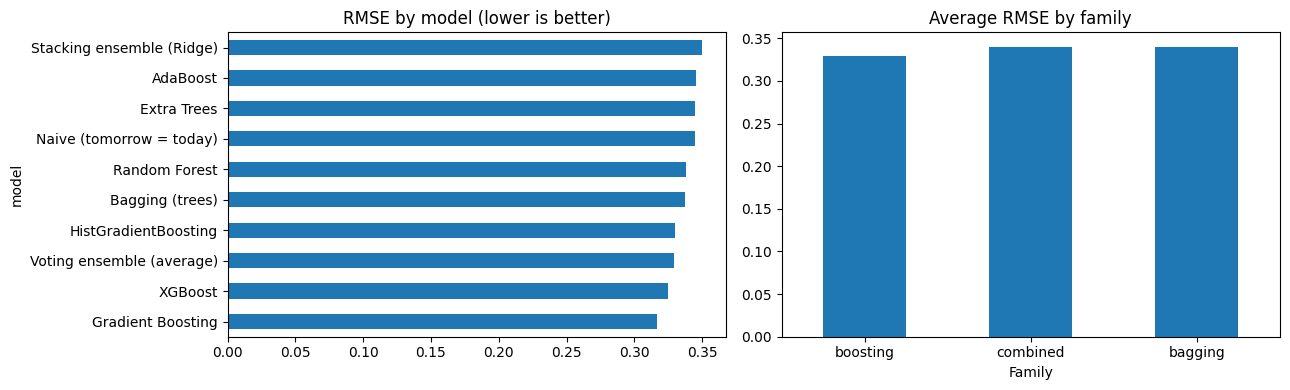

In [6]:
fam = table.drop(index="Naive (tomorrow = today)").groupby("Family")["RMSE (% return)"].mean().sort_values()
display(fam.round(4).to_frame("avg RMSE"))
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
table["RMSE (% return)"].sort_values().plot.barh(ax=ax[0], title="RMSE by model (lower is better)")
fam.plot.bar(ax=ax[1], title="Average RMSE by family", rot=0)
plt.tight_layout(); plt.show()

## 5. Cumulative absolute error over the test period
The best model's line should stay low throughout, not only at the end.

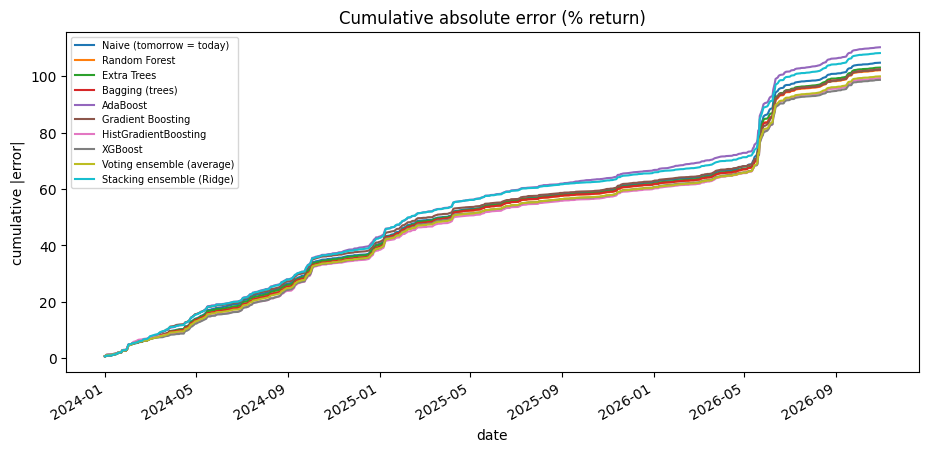

In [7]:
t = res["test"].set_index("date")
models = [c for c in t.columns if c not in ("mid", "target")]
cum = pd.DataFrame({m: (t["target"] - t[m]).abs().cumsum() for m in models})
cum.plot(figsize=(11, 5), title="Cumulative absolute error (% return)")
plt.ylabel("cumulative |error|"); plt.legend(fontsize=7); plt.show()

## 6. Predicted vs actual (last 120 test days)

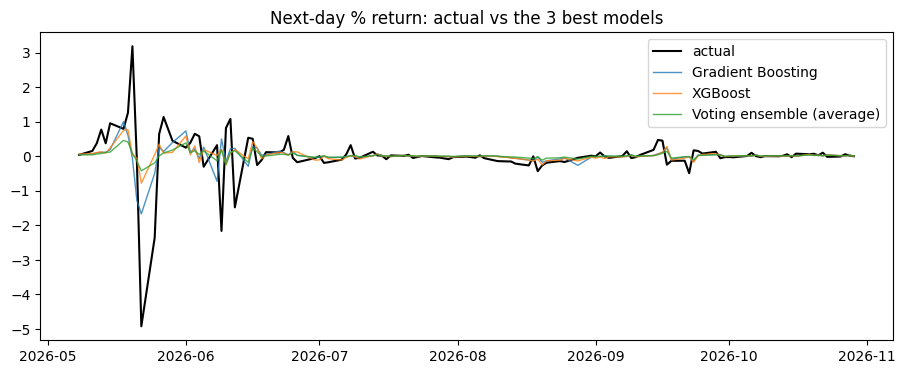

In [8]:
top3 = table.drop(index="Naive (tomorrow = today)")["RMSE (% return)"].nsmallest(3).index.tolist()
sub = t.tail(120)
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(sub.index, sub["target"], color="black", lw=1.5, label="actual")
for m in top3:
    ax.plot(sub.index, sub[m], lw=1, alpha=0.8, label=m)
ax.set_title("Next-day % return: actual vs the 3 best models"); ax.legend(); plt.show()

## 7. Feature importance (tree models)

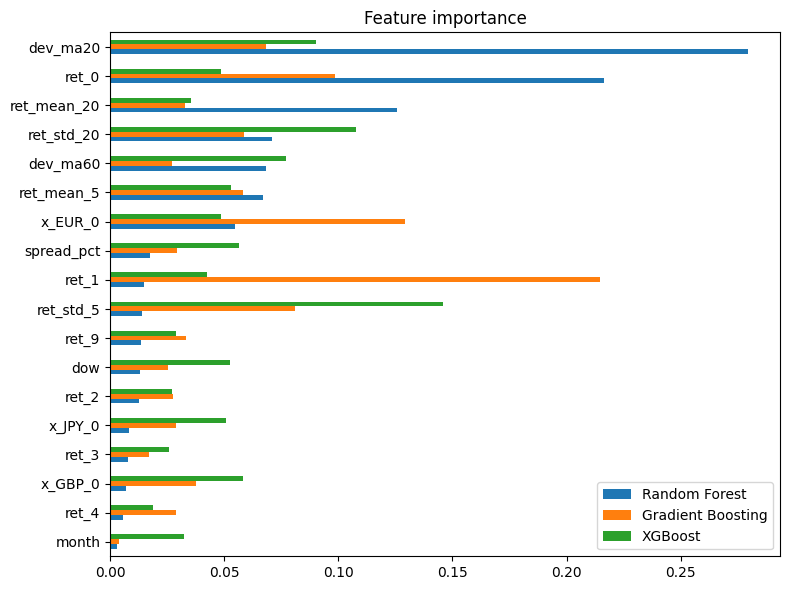

In [9]:
imp = res["importances"]
show = [m for m in ["Random Forest", "Gradient Boosting", "XGBoost"] if m in imp.columns] or list(imp.columns)[:2]
imp[show].sort_values(show[0]).plot.barh(figsize=(8, 6), title="Feature importance")
plt.tight_layout(); plt.show()

## 8. Stacking weights
How much each base model counts in the stacked forecast (Ridge coefficients).

,Ridge weight
Random Forest,1.482
Gradient Boosting,-0.072
HistGradientBoosting,-0.361


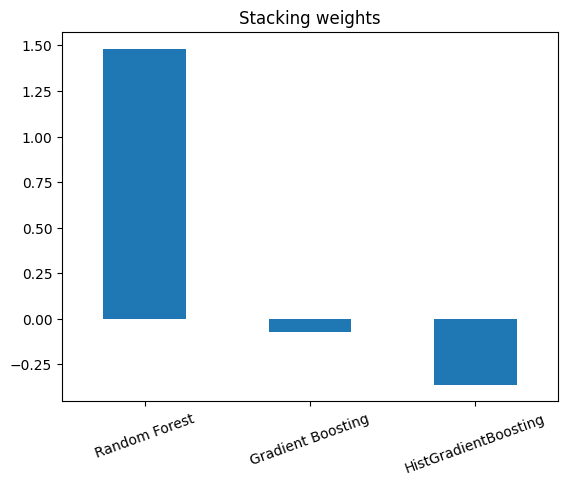

In [10]:
w = res["weights"]
display(w.round(3).to_frame())
w.plot.bar(title="Stacking weights", rot=20); plt.show()

## 9. Is the ranking stable?
Re-runs without stacking and with 100 trees to save time. If the best model keeps changing, the models are effectively equal.

In [11]:
quick = {**PARAMS, "n_estimators": 100}
# (a) different random seeds
seed_cols = {}
for s in range(3):
    r = run_ensemble_experiment(X, TRAIN_END, {**quick, "seed": s}, selected=SELECTED)
    seed_cols[f"seed {s}"] = r["table"]["RMSE (% return)"]
by_seed = pd.DataFrame(seed_cols)
by_seed["mean"], by_seed["std"] = by_seed.mean(axis=1), by_seed.std(axis=1)
display(by_seed.sort_values("mean").round(4))

,seed 0,seed 1,seed 2,mean,std
model,,,,,
Gradient Boosting,0.3184,0.3188,0.3191,0.3188,0.0004
HistGradientBoosting,0.3271,0.3271,0.3271,0.3271,0.0000
XGBoost,0.3328,0.3341,0.3325,0.3331,0.0008
Bagging (trees),0.3338,0.3363,0.3378,0.3360,0.0020
Random Forest,0.3366,0.3383,0.3400,0.3383,0.0017
Extra Trees,0.3433,0.3429,0.3438,0.3433,0.0005
Naive (tomorrow = today),0.3446,0.3446,0.3446,0.3446,0.0000
AdaBoost,0.3447,0.3458,0.3443,0.3449,0.0008


In [12]:
# (b) different training end dates (2021 means the test period includes the 2022 crisis)
split_cols = {}
for end in ["2021-12-31", "2022-12-31", "2023-12-31", "2024-12-31"]:
    r = run_ensemble_experiment(X, end, quick, selected=SELECTED)
    split_cols[end] = r["table"]["RMSE (% return)"]
by_split = pd.DataFrame(split_cols)
display(by_split.round(4))
print("Best model per split:")
print(by_split.idxmin())

,2021-12-31,2022-12-31,2023-12-31,2024-12-31
model,,,,
Naive (tomorrow = today),0.7181,0.4992,0.3446,0.3862
Random Forest,0.7119,0.4971,0.3387,0.3800
Extra Trees,0.7144,0.5040,0.3444,0.3873
Bagging (trees),0.7104,0.4888,0.3383,0.3787
AdaBoost,0.7170,0.5012,0.3451,0.3834
Gradient Boosting,0.7759,0.5337,0.3156,0.3449
HistGradientBoosting,0.7379,0.4983,0.3271,0.3694
XGBoost,0.7358,0.4962,0.3244,0.3474


Best model per split:
2021-12-31      Bagging (trees)
2022-12-31      Bagging (trees)
2023-12-31    Gradient Boosting
2024-12-31    Gradient Boosting
dtype: object


## 10. Bagging vs boosting vs stacking: summary

| Method | How it works | Strengths | Limitations |
|---|---|---|---|
| **Bagging** (Random Forest, Extra Trees) | Many trees trained independently on random samples, predictions averaged | Reduces variance, hard to overfit | Cannot fix bias; can average away weak real signals |
| **Boosting** (AdaBoost, Gradient Boosting, XGBoost, LightGBM, CatBoost) | Trees built one after another, each correcting the last | Often most accurate on tabular data | More tuning; can overfit noisy data |
| **Voting** | Simple average of chosen models | Easy and robust | Weak models drag the average down |
| **Stacking** | A meta-model learns the weights | Can beat every single model | Slow, can overfit, needs time-aware validation |

**Tabular vs image/text:** tree ensembles are usually strongest on tabular data like this table (mixed numeric features, modest rows).
For images and text, deep learning usually wins because it learns features from raw pixels or words, which trees cannot do.

## 11. Conclusion (edit after running)
- Best model by RMSE / MAE / direction: ...
- Bagging vs boosting: ...
- Did voting or stacking beat the best single model? ...
- Is the ranking stable across seeds and split dates? ...
- Caveat: gaps between models are small, so call them comparable unless the ranking is consistent.